# Marketing Campaign Effectiveness — A/B Test Analysis

## Objective
Compare conversion rates for users shown product advertisements and users shown a public-service announcement (PSA).

The analysis measures the conversion lift, tests whether the observed difference is statistically significant, and assesses it against a predefined planning threshold. It also examines the sample size needed to detect a worthwhile improvement.

**Primary metric:** Conversion rate  
**Significance level:** 5% (two-sided)  
**Confidence level:** 95%  
**Target power:** 80%  
**Minimum worthwhile lift:** 0.5 percentage points, used as a planning assumption.

The threshold is not a profitability target. The dataset does not include advertising costs or revenue.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

DATA_PATH = Path("../data/raw/marketing_AB.csv")

ALPHA = 0.05
CONFIDENCE_LEVEL = 0.95
TARGET_POWER = 0.80
MIN_WORTHWHILE_LIFT = 0.005
BOOTSTRAP_REPS = 10_000

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv(DATA_PATH)

required_columns = [
    "user id",
    "test group",
    "converted",
    "total ads",
    "most ads day",
    "most ads hour",
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

if df[required_columns].isna().any().any():
    raise ValueError("Missing values found in the required columns.")

if df["user id"].duplicated().any():
    raise ValueError("Duplicate user IDs found. Resolve them before analysis.")

if not set(df["test group"].unique()).issubset({"ad", "psa"}):
    raise ValueError("Unexpected values found in test group.")

if set(df["test group"].unique()) != {"ad", "psa"}:
    raise ValueError("Both ad and psa groups must be present.")

if not set(df["converted"].unique()).issubset({0, 1}):
    raise ValueError("Conversion must contain only 0 and 1.")

if not pd.api.types.is_numeric_dtype(df["total ads"]):
    raise ValueError("total ads must be numeric.")

if (df["total ads"] < 0).any():
    raise ValueError("Negative ad exposure counts found.")

print(f"Rows: {len(df):,}")
print(f"Unique users: {df['user id'].nunique():,}")
print("Validation checks passed.")

Rows: 588,101
Unique users: 588,101
Validation checks passed.


## Conversion rates

First, compare the number of users and conversions in each group. The allocation is unequal, so the group sizes should be considered when interpreting the precision and power of the test.

,users,conversions,conversion_rate,conversion_rate_pct,group_share_pct
test group,,,,,
ad,564577,14423,0.0255,2.5547,96.0000
psa,23524,420,0.0179,1.7854,4.0000


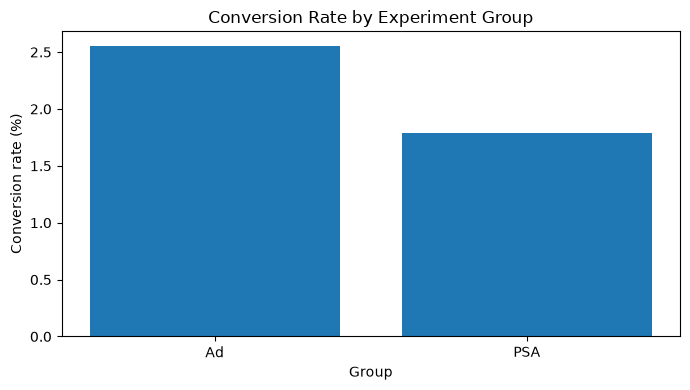

Ad group share: 96.00%
PSA group share: 4.00%


In [3]:
summary = (
    df.groupby("test group")["converted"]
    .agg(users="size", conversions="sum", conversion_rate="mean")
    .reindex(["ad", "psa"]))

summary["conversion_rate_pct"] = summary["conversion_rate"] * 100
summary["group_share_pct"] = summary["users"] / len(df) * 100
display(summary)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Ad", "PSA"],
    summary.loc[["ad", "psa"], "conversion_rate_pct"],)

ax.set_title("Conversion Rate by Experiment Group")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("Group")

plt.tight_layout()
plt.show()

n_ad = int(summary.loc["ad", "users"])
n_psa = int(summary.loc["psa", "users"])
conversions_ad = int(summary.loc["ad", "conversions"])
conversions_psa = int(summary.loc["psa", "conversions"])

p_ad = conversions_ad / n_ad
p_psa = conversions_psa / n_psa

print(f"Ad group share: {n_ad / len(df):.2%}")
print(f"PSA group share: {n_psa / len(df):.2%}")

## Hypothesis test and conversion lift

The null hypothesis is that both groups have the same conversion rate. The alternative is that their conversion rates differ.

- H₀: p_ad = p_psa
- H₁: p_ad ≠ p_psa

The test is two-sided at a 5% significance level. Alongside the p-value, the effect size and its confidence interval matter because a large sample can make a small difference statistically significant.

In [4]:
z_stat, p_value = proportions_ztest(
    count=[conversions_ad, conversions_psa],
    nobs=[n_ad, n_psa],
    alternative="two-sided",)

absolute_lift = p_ad - p_psa
relative_lift = absolute_lift / p_psa if p_psa > 0 else np.nan

ci_low, ci_high = confint_proportions_2indep(
    count1=conversions_ad,
    nobs1=n_ad,
    count2=conversions_psa,
    nobs2=n_psa,
    method="newcomb",
    compare="diff",
    alpha=ALPHA,)

print(f"Ad conversion rate: {p_ad:.2%}")
print(f"PSA conversion rate: {p_psa:.2%}")
print(f"Absolute lift: {absolute_lift * 100:.3f} percentage points")
print(f"Relative lift: {relative_lift:.2%}")
print(f"95% CI for absolute lift: [{ci_low * 100:.3f}, {ci_high * 100:.3f}] percentage points")
print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.6g}")
print(f"Incremental conversions per 1,000 users: {absolute_lift * 1000:.2f}")

if p_value < ALPHA:
    print("Result: Reject the null hypothesis at the 5% significance level.")
else:
    print("Result: Do not reject the null hypothesis at the 5% significance level.")

Ad conversion rate: 2.55%
PSA conversion rate: 1.79%
Absolute lift: 0.769 percentage points
Relative lift: 43.09%
95% CI for absolute lift: [0.587, 0.936] percentage points
Z-statistic: 7.370
P-value: 1.70528e-13
Incremental conversions per 1,000 users: 7.69
Result: Reject the null hypothesis at the 5% significance level.


In [5]:
rng = np.random.default_rng(42)

ad_boot = rng.binomial(n_ad, p_ad, size=BOOTSTRAP_REPS) / n_ad
psa_boot = rng.binomial(n_psa, p_psa, size=BOOTSTRAP_REPS) / n_psa

valid = psa_boot > 0
relative_lift_boot = (ad_boot[valid] - psa_boot[valid]) / psa_boot[valid]

rel_ci_low, rel_ci_high = np.percentile(
    relative_lift_boot,
    [2.5, 97.5],
)

print(f"Bootstrap 95% CI for relative lift: [{rel_ci_low:.2%}, {rel_ci_high:.2%}]")

Bootstrap 95% CI for relative lift: [30.54%, 57.72%]


## Practical significance

The planning threshold is a minimum worthwhile improvement of 0.5 percentage points in absolute conversion rate. Compare the observed lift and its confidence interval with this threshold.

This is an assumed decision threshold, not a value derived from campaign economics. It cannot establish profitability.

In [6]:
threshold_cleared = absolute_lift >= MIN_WORTHWHILE_LIFT
ci_above_threshold = ci_low > MIN_WORTHWHILE_LIFT

print(f"Minimum worthwhile lift: {MIN_WORTHWHILE_LIFT * 100:.2f} percentage points")
print(f"Observed lift meets threshold: {threshold_cleared}")
print(f"95% CI is entirely above threshold: {ci_above_threshold}")

if threshold_cleared and ci_above_threshold:
    print("The estimated lift meets the threshold, and the confidence interval is above it.")
elif threshold_cleared:
    print("The point estimate meets the threshold, but uncertainty remains around the size of the lift.")
else:
    print("The estimated lift does not meet the planning threshold.")

Minimum worthwhile lift: 0.50 percentage points
Observed lift meets threshold: True
95% CI is entirely above threshold: True
The estimated lift meets the threshold, and the confidence interval is above it.


## Power and sample-size planning

Estimate the sample size needed to detect a 0.5-percentage-point improvement with 80% power and a two-sided 5% significance level. The calculation uses the observed PSA conversion rate as the baseline.

The current group allocation is also compared with equal-sized groups. These are planning estimates; they do not establish why the original groups were assigned in their observed proportions.

In [7]:
power_analysis = NormalIndPower()

baseline_rate = p_psa
target_rate = baseline_rate + MIN_WORTHWHILE_LIFT

if baseline_rate <= 0 or target_rate >= 1:
    raise ValueError("The observed baseline rate cannot support this planning calculation.")

effect_size = proportion_effectsize(baseline_rate, target_rate)
current_ratio = n_ad / n_psa

required_per_group = power_analysis.solve_power(
    effect_size=effect_size,
    power=TARGET_POWER,
    alpha=ALPHA,
    ratio=1,
    alternative="two-sided",)

required_psa_current_ratio = power_analysis.solve_power(
    effect_size=effect_size,
    power=TARGET_POWER,
    alpha=ALPHA,
    ratio=current_ratio,
    alternative="two-sided",)

mde_effect = power_analysis.solve_power(
    effect_size=None,
    nobs1=n_psa,
    alpha=ALPHA,
    power=TARGET_POWER,
    ratio=current_ratio,
    alternative="two-sided",)

mde_rate = np.sin(
    (mde_effect + 2 * np.arcsin(np.sqrt(baseline_rate))) / 2) ** 2 - baseline_rate

estimated_power = power_analysis.power(
    effect_size=effect_size,
    nobs1=n_psa,
    alpha=ALPHA,
    ratio=current_ratio,
    alternative="two-sided",)

print(f"Target improvement: {MIN_WORTHWHILE_LIFT * 100:.2f} percentage points")
print(f"Required users per group with equal allocation: {np.ceil(required_per_group):,.0f}")
print(f"Required PSA users at current allocation ratio: {np.ceil(required_psa_current_ratio):,.0f}")
print(f"Corresponding ad users at current ratio: {np.ceil(required_psa_current_ratio * current_ratio):,.0f}")
print(f"Estimated power at current sample sizes: {estimated_power:.2%}")
print(f"Approximate MDE at 80% power: {mde_rate * 100:.3f} percentage points")

Target improvement: 0.50 percentage points
Required users per group with equal allocation: 12,474
Required PSA users at current allocation ratio: 6,497
Corresponding ad users at current ratio: 155,921
Estimated power at current sample sizes: 99.96%
Approximate MDE at 80% power: 0.255 percentage points
